In [2]:
import cv2
import numpy as np
import imutils
from matplotlib import pyplot as plt

More tutorials on opencv can be found:

https://docs.opencv.org/master/d2/d96/tutorial_py_table_of_contents_imgproc.html

In [3]:
# Path to the input image we will process throughout the tutorial.
path = "tetris_blocks.png"

# Image input and initial processing
Load the input image (whose path was supplied via command line argument) and display the image to our screen:

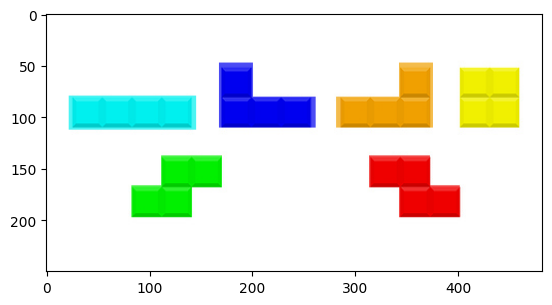

In [4]:
# Load the image from disk and prepare it for display/processing.
# cv2.imread() reads images in BGR channel order (OpenCV's default),
# but matplotlib expects RGB order. If we don't convert, colors will look
# wrong (e.g. blue and red swapped) when we plot with plt.imshow().
# Split the image into its Blue, Green, Red channels, then merge them
# back together in Red, Green, Blue order.
bgr_img = cv2.imread(path)
b,g,r = cv2.split(bgr_img)       # get b,g,r
image = cv2.merge([r,g,b])
plt.imshow(image)

Convert the image to grayscale:

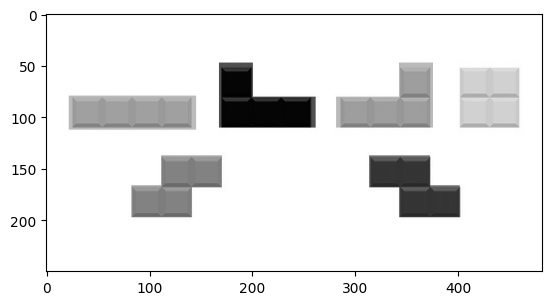

In [5]:
# Convert the RGB image to grayscale.
# Many classic CV operations (edge detection, thresholding, contour
# finding) work on single-channel intensity images, not color images.
# Reducing to one channel also simplifies and speeds up later processing,
# since we no longer need to reason about 3 color channels at once.
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
plt.imshow(gray, cmap = 'gray')

# Advanced processing
Apply edge detection, so we can find the outlines of objects in images:


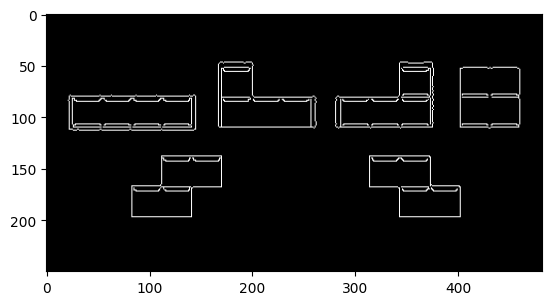

In [6]:
# Apply Canny edge detection.
# Edges are pixels where intensity changes sharply, which usually
# correspond to object boundaries. Visualizing edges is a good sanity
# check before we try to segment (threshold) the image, since it shows
# us roughly where the objects and their outlines are.
# cv2.Canny(image, lower_threshold, upper_threshold). Gradients
# above the upper threshold are always treated as edges, gradients below
# the lower threshold are discarded, and gradients in between are kept
# only if they connect to a strong edge.
edged = cv2.Canny(gray, 30, 150)
plt.imshow(edged, cmap='gray')

Threshold the image by setting all pixel values equal to or less than 225 to 255 (white; foreground): $x \le 225 \rightarrow x = 255$ and all pixel values greater than 225 to 0 (black; background): $x \gt 225 \rightarrow x=0$

Thereby we are segmenting the image.

Both the threshold (e.g. 225 in our case) and the value for pixels less than the threshold in the resulting image (255 in our case) can be tweaked.

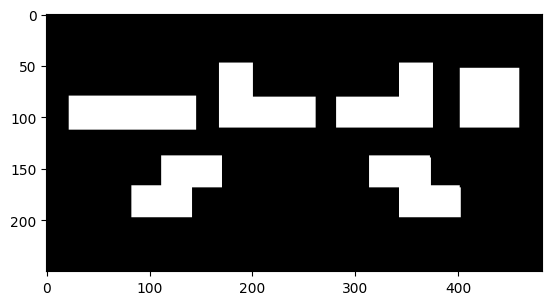

In [7]:
# Binary (inverse) thresholding to segment foreground from background.
# Thresholding turns the grayscale image into a black-and-white
# "mask" that cleanly separates the objects we care about (foreground)
# from everything else (background), which is a prerequisite for finding
# contours in the next step.
# cv2.THRESH_BINARY_INV flips the usual behavior. Pixels with
# intensity <= threshold become white (255, foreground) and pixels with
# intensity > threshold become black (0, background).
threshold = 225
threshold_value = 255

thresh = cv2.threshold(gray, threshold, threshold_value, cv2.THRESH_BINARY_INV)[1]
plt.imshow(thresh, cmap='gray')

Find contours (i.e., outlines) of the foreground objects in the thresholded image:

In [8]:
# Find the contours (outlines) of the foreground objects in the mask.
# Contours let us identify and later count/manipulate individual
# objects, rather than just having a blob of white pixels.
#   - cv2.RETR_EXTERNAL only returns the outermost contours (ignores
#     nested/inner contours), since we only care about whole objects here.
#   - cv2.CHAIN_APPROX_SIMPLE compresses straight contour segments into
#     just their endpoints, saving memory.
#   - imutils.grab_contours() is needed because different OpenCV versions
#     return findContours() results in a different tuple structure; this
#     helper normalizes it into just the list of contours.
#   - We work on a copy of thresh and a copy of the original image (output)
#     so the originals remain untouched for later steps.
cnts = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts = imutils.grab_contours(cnts)
output = image.copy()

Loop over the contours:

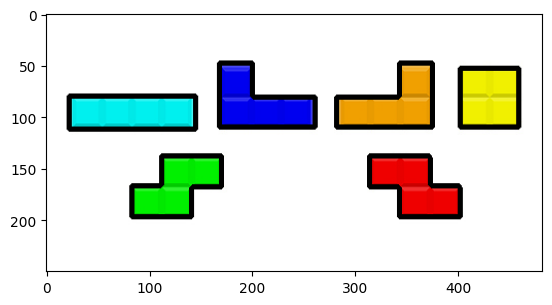

In [9]:
# Draw every detected contour onto the output image.
# This visually verifies that the contours we found actually line up
# with the real object boundaries in the image. For each contour c,
# draw it in black (0, 0, 0) with a line thickness of 3 pixels
# directly on top of the color image.
for c in cnts:
    cv2.drawContours(output, [c], -1, (0, 0, 0), 3)

plt.imshow(output)

Draw the total number of contours found in purple:

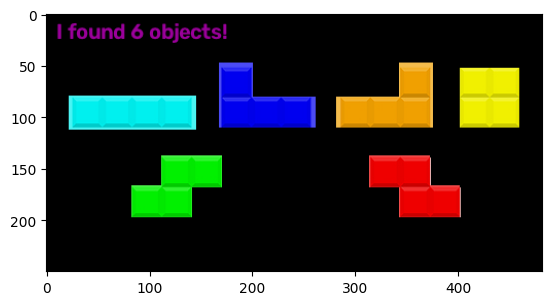

In [20]:
# Annotate the image with the total object count.
# cv2.putText() draws the given string at position (10, 25) using a
# simple font, scale 0.7, in purple ((155, 0, 155) in RGB), with
# thickness 2.
text = "I found {} objects!".format(len(cnts))
cv2.putText(output, text, (10, 25),  cv2.FONT_HERSHEY_SIMPLEX, 0.7, (155, 0, 155), 2)
plt.imshow(output)

We apply erosions to reduce the size of foreground objects:

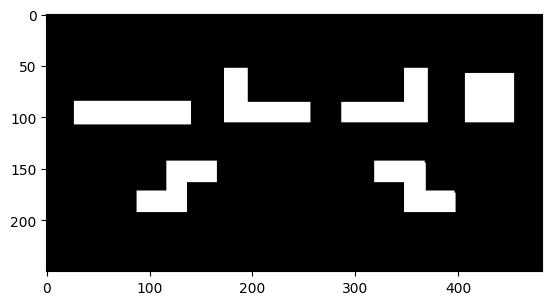

In [11]:
# Erosion: shrink the white (foreground) regions of the mask.
# Erosion is useful for removing small noise specks and for
# separating objects that are touching/overlapping, by "eating away" at
# the boundaries of foreground regions.
# We erode a fresh copy of the threshold mask (so we don't affect
# the original 'thresh') using a default 3x3 kernel, applied 5 times
# (iterations=5) to make the shrinking effect clearly visible.
mask = thresh.copy()
mask = cv2.erode(mask, None, iterations = 5)
plt.imshow(mask, cmap = 'gray')

Similarly, dilations can increase the size of the ground objects:

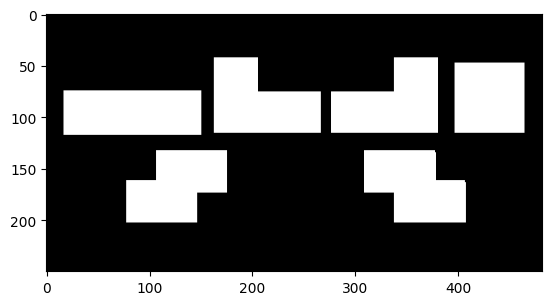

In [12]:
# Dilation: grow the white (foreground) regions of the mask.
# Dilation is the opposite of erosion. It's useful for closing small
# holes/gaps inside objects or for merging nearby regions that should be
# considered one object.
# Same default kernel as erosion, applied 5 times, but this time
# growing instead of shrinking the foreground.
mask = thresh.copy()
mask = cv2.dilate(mask, None, iterations = 5)
plt.imshow(mask, cmap='gray')

A typical operation we may want to apply is to take our mask and apply a bitwise `AND` to our input image, keeping only the masked regions:

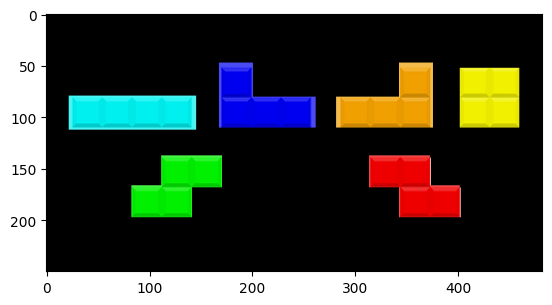

In [13]:
# Apply the mask to the original image using a bitwise AND.
# This keeps only the pixels of the original color image that fall
# inside the foreground mask, effectively "cutting out" the detected
# objects and blacking out everything else. It's a common last step to
# go from "a mask of where objects are" to "an image showing just the
# objects". cv2.bitwise_and(image, image, mask=mask) keeps image pixels where
# mask is non-zero (white) and sets everything else to zero (black).
mask = thresh.copy()
output = cv2.bitwise_and(image, image, mask=mask)
plt.imshow(output)

# Exercise 2
1. Can you remove the yellow square from the image?
2. Go through the tutorial, but with the `spheres.png` image. (replace `tetris_blocks.png` with `spheres.png`)
3. Tweak the parameters of the thresholding. Can you threshold all the spheres?
4. Can you remove the red sphere?
5. Can you remove the green sphere?

In [1]:
import cv2
import numpy as np
import imutils
from matplotlib import pyplot as plt

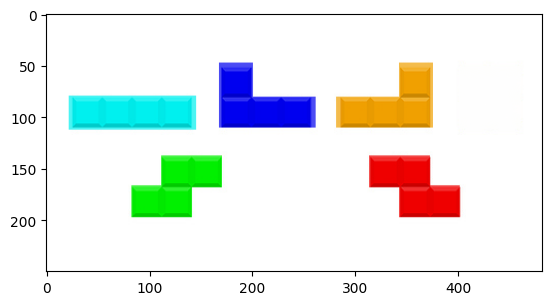

In [ ]:
# ============================================================
# 1. Remove the yellow square from the image
# ============================================================
# In RGB, a given color (e.g. "yellow") can be spread across a complicated
# range of R/G/B combinations depending on brightness. In HSV (Hue,
# Saturation, Value), the Hue channel alone captures "what color" a pixel is,
# independent of how light/dark or saturated it is. So thresholding on a narrow
# Hue range is a much more robust way to isolate a specific color like yellow.
#   1. Reload the image and convert BGR -> RGB, same as before.
#   2. Convert RGB -> HSV.
#   3. cv2.inRange() builds a binary mask of all pixels whose HSV values
#      fall inside the given lower/upper bounds (i.e. "yellow" pixels).
#   4. Morphological opening (erode then dilate) removes small noisy
#      specks from the mask without significantly changing the shape of
#      the main yellow region.
#   5. Dilating the mask slightly afterward ensures we cover the full
#      extent of the yellow square, including its edges/anti-aliasing.
#   6. cv2.inpaint() then "fills in" the masked-out region by intelligently
#      reconstructing it from the surrounding image texture (INPAINT_TELEA
#      algorithm), so the square disappears seamlessly instead of leaving
#      a black or flat-colored hole.
path = "tetris_blocks.png"

bgr_img = cv2.imread(path)
b, g, r = cv2.split(bgr_img)
image = cv2.merge([r, g, b])

hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
lower_yellow = np.array([25, 150, 150])
upper_yellow = np.array([35, 255, 255])
yellow_mask = cv2.inRange(hsv, lower_yellow, upper_yellow)

kernel = np.ones((3, 3), np.uint8)
yellow_mask = cv2.morphologyEx(yellow_mask, cv2.MORPH_OPEN, kernel, iterations=1)
yellow_mask = cv2.dilate(yellow_mask, None, iterations=1)

no_yellow = cv2.inpaint(image, yellow_mask, inpaintRadius=5, flags=cv2.INPAINT_TELEA)

plt.figure()
plt.imshow(no_yellow)
plt.show()

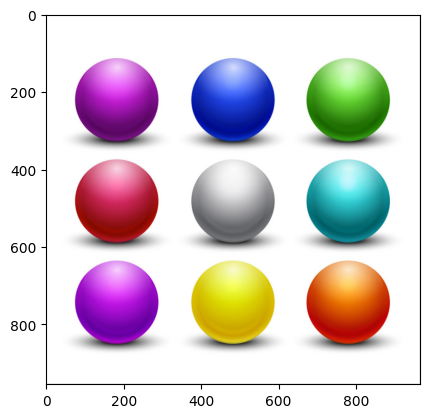

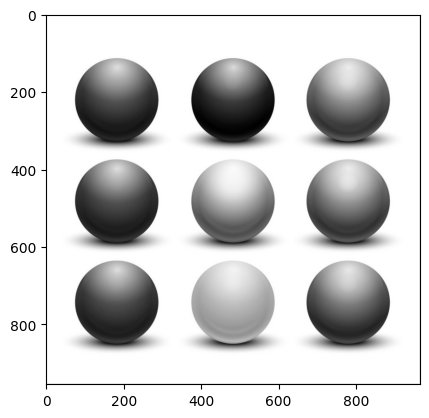

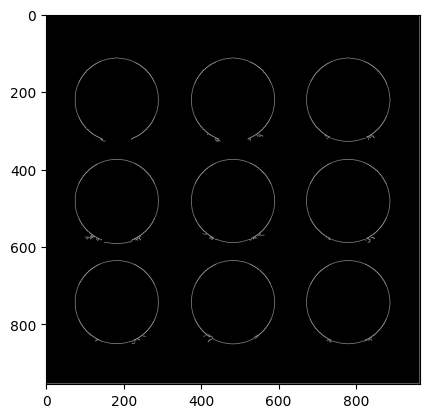

In [16]:
# ============================================================
# 2. Repeat the tutorial steps with spheres.png
# ============================================================
# This checks that the grayscale -> edge detection pipeline we built
# for the tetris blocks generalizes to a different image with different
# objects (spheres instead of rectangular blocks). Identical to the
# "Image input and initial processing" and "Advanced processing"
# sections above. Load & convert to RGB, convert to grayscale,
# then run Canny edge detection.
path2 = "spheres.png"

image2 = cv2.cvtColor(cv2.imread("spheres.png"), cv2.COLOR_BGR2RGB)
plt.imshow(image2)
plt.show()

gray2 = cv2.cvtColor(image2, cv2.COLOR_RGB2GRAY)
plt.imshow(gray2, cmap='gray')
plt.show()

edged2 = cv2.Canny(gray2, 30, 150)
plt.imshow(edged2, cmap='gray')
plt.show()

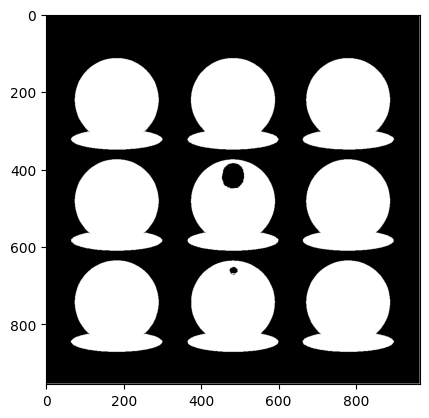

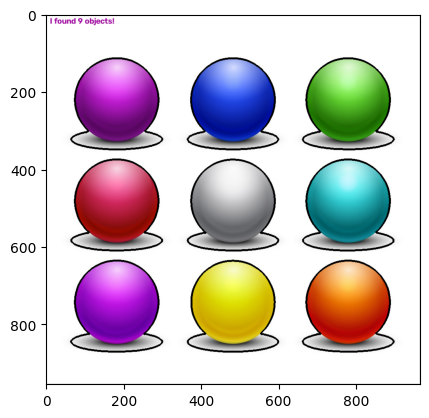

In [ ]:
# ============================================================
# 3. Tweak thresholding parameters to segment all spheres
# ============================================================
# The tetris-block threshold (225) does not necessarily segment every sphere
# correctly, since these spheres can have different brightness levels than
# the blocks. Threshold values are very image-dependent, so we adjust it
# (here to 240) and inspect the resulting mask directly. cv2.findContours
# can sometimes pick up the image border itself as a "contour" if the
# thresholded mask touches the edge of the frame; explicitly setting the
# outermost rows/columns of thresh2 to 0 (black) prevents this artifact. After
# thresholding there can be tiny, irrelevant blobs of noise identified as
# separate contours; keeping only contours with an area > 200 pixels removes
# these spurious detections while keeping the real spheres. The remaining steps
# (find contours, draw them, overlay the count) are the same as in the original
# tutorial.
threshold = 240
threshold_value = 255

thresh2 = cv2.threshold(gray2, threshold, threshold_value, cv2.THRESH_BINARY_INV)[1]
plt.imshow(thresh2, cmap='gray')
plt.show()

thresh2[0, :] = 0
thresh2[-1, :] = 0
thresh2[:, 0] = 0
thresh2[:, -1] = 0

cnts2 = cv2.findContours(thresh2.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cnts2 = imutils.grab_contours(cnts2)
cnts2 = [c for c in cnts2 if cv2.contourArea(c) > 200]
output2 = image2.copy()
for c in cnts2:
    cv2.drawContours(output2, [c], -1, (0, 0, 0), 3)

text = "I found {} objects!".format(len(cnts2))
cv2.putText(output2, text, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (155, 0, 155), 2)
plt.imshow(output2)
plt.show()

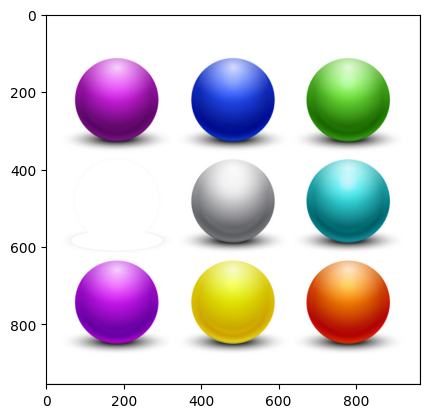

In [18]:
# ============================================================
# 4. Remove the red sphere
# ============================================================
# Why compute the mean color per contour rather than a fixed color mask:
# It's more robust to lighting/shading gradients across a single sphere,
# and it lets us reason about "is this particular object red?" on a
# per-object basis rather than trying to build one global color mask that
# might also catch red-ish highlights on other spheres.
#   1. For each contour, build a filled binary mask covering just that
#      one object (cv2.drawContours with thickness=-1 fills the shape).
#   2. cv2.mean(image2, mask=mask2) computes the average R, G, B value of
#      the image restricted to that mask (i.e. the object's average
#      color).
#   3. A simple rule identifies "red": red channel clearly higher than
#      both green and blue (by more than 60), and green is low (<100),
#      which distinguishes true red from e.g. orange or pink.
#   4. Pixels belonging to a contour matching this rule are painted white,
#      effectively erasing that sphere from the output image.
output3 = image2.copy()

for c in cnts2:
    mask2 = np.zeros(image2.shape[:2], dtype="uint8")
    cv2.drawContours(mask2, [c], -1, 255, -1)
    mean_val = cv2.mean(image2, mask=mask2)
    r, g, b = mean_val[0], mean_val[1], mean_val[2]
    if r > g + 60 and r > b + 60 and g < 100:
        output3[mask2 > 0] = [255, 255, 255]

plt.imshow(output3)

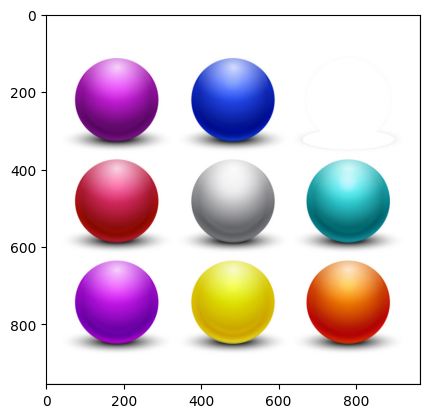

In [19]:
# ============================================================
# Part 5: Remove the green sphere
# ============================================================
# Same per-object mean-color approach as Part 4, just with a
# different color rule, to show the method generalizes to other colors.
# Identical to Part 4, except the color test now checks that green
# is clearly higher than both red and blue (by more than 30), which
# identifies the green sphere instead of the red one.
output4 = image2.copy()

for c in cnts2:
    mask3 = np.zeros(image2.shape[:2], dtype="uint8")
    cv2.drawContours(mask3, [c], -1, 255, -1)
    mean_val = cv2.mean(image2, mask=mask3)
    r, g, b = mean_val[0], mean_val[1], mean_val[2]
    if g > r + 30 and g > b + 30:
        output4[mask3 > 0] = [255, 255, 255]

plt.imshow(output4)
plt.show()